# 04 Linearity and Nonlinearity
Use binned churn rates and mutual information; normality is not treated as a linearity test.

In [9]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_loader import load_raw_data
from src.linearity_analysis import binned_churn_rates, diagnose_relationship

data = load_raw_data(PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
continuous_features = ["tenure", "MonthlyCharges", "TotalCharges"]
data["Churn"] = data["Churn"].astype(int)
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


tenure: monotonic; assess whether nonlinear or approximately linear on the logit scale


,bin,customer_count,churn_rate,logit_churn_rate,bin_label
0,"(-0.001, 2.0]",862,0.583527,0.337268,"(-0.001, 2.0]"
1,"(2.0, 6.0]",619,0.453958,-0.184691,"(2.0, 6.0]"
2,"(6.0, 12.0]",705,0.358865,-0.580293,"(6.0, 12.0]"
3,"(12.0, 20.0]",692,0.309249,-0.803635,"(12.0, 20.0]"
4,"(20.0, 29.0]",691,0.228654,-1.215926,"(20.0, 29.0]"
5,"(29.0, 40.0]",717,0.218968,-1.271691,"(29.0, 40.0]"
6,"(40.0, 50.0]",652,0.176380,-1.541066,"(40.0, 50.0]"
7,"(50.0, 60.0]",698,0.136103,-1.848040,"(50.0, 60.0]"
8,"(60.0, 69.0]",756,0.092593,-2.282382,"(60.0, 69.0]"
9,"(69.0, 72.0]",651,0.035330,-3.307046,"(69.0, 72.0]"


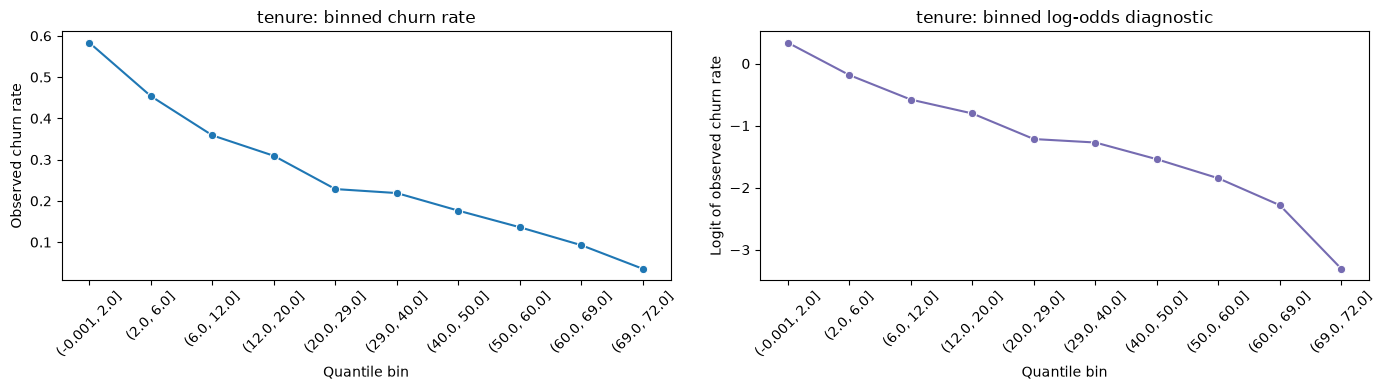

MonthlyCharges: non-monotonic or threshold-driven


,bin,customer_count,churn_rate,logit_churn_rate,bin_label
0,"(18.249, 20.05]",717,0.085077,-2.375287,"(18.249, 20.05]"
1,"(20.05, 25.05]",703,0.098151,-2.217942,"(20.05, 25.05]"
2,"(25.05, 45.85]",695,0.254676,-1.073826,"(25.05, 45.85]"
3,"(45.85, 58.83]",702,0.245014,-1.125383,"(45.85, 58.83]"
4,"(58.83, 70.35]",711,0.215190,-1.293921,"(58.83, 70.35]"
5,"(70.35, 79.1]",700,0.381429,-0.483489,"(70.35, 79.1]"
6,"(79.1, 85.5]",705,0.378723,-0.494970,"(79.1, 85.5]"
7,"(85.5, 94.25]",702,0.343305,-0.648601,"(85.5, 94.25]"
8,"(94.25, 102.6]",704,0.409091,-0.367725,"(94.25, 102.6]"
9,"(102.6, 118.75]",704,0.247159,-1.113822,"(102.6, 118.75]"


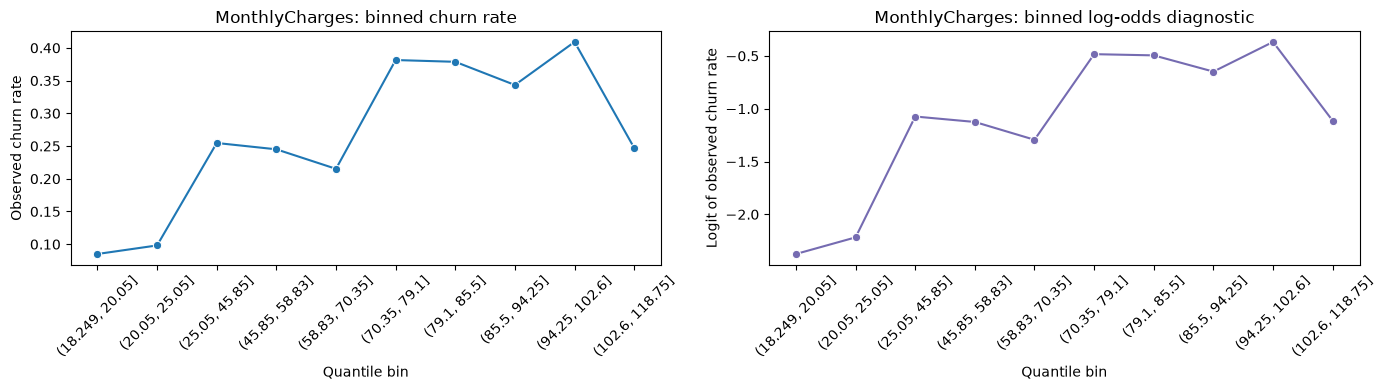

TotalCharges: non-monotonic or threshold-driven


,bin,customer_count,churn_rate,logit_churn_rate,bin_label
0,"(18.799, 84.6]",705,0.523404,0.093685,"(18.799, 84.6]"
1,"(84.6, 267.07]",702,0.396011,-0.422112,"(84.6, 267.07]"
2,"(267.07, 551.995]",703,0.305832,-0.819677,"(267.07, 551.995]"
3,"(551.995, 944.17]",703,0.273115,-0.978874,"(551.995, 944.17]"
4,"(944.17, 1397.475]",703,0.220484,-1.262850,"(944.17, 1397.475]"
5,"(1397.475, 2048.95]",703,0.194879,-1.418613,"(1397.475, 2048.95]"
6,"(2048.95, 3141.13]",703,0.281650,-0.936291,"(2048.95, 3141.13]"
7,"(3141.13, 4475.41]",703,0.179232,-1.521560,"(3141.13, 4475.41]"
8,"(4475.41, 5976.64]",703,0.157895,-1.673976,"(4475.41, 5976.64]"
9,"(5976.64, 8684.8]",704,0.125000,-1.945910,"(5976.64, 8684.8]"


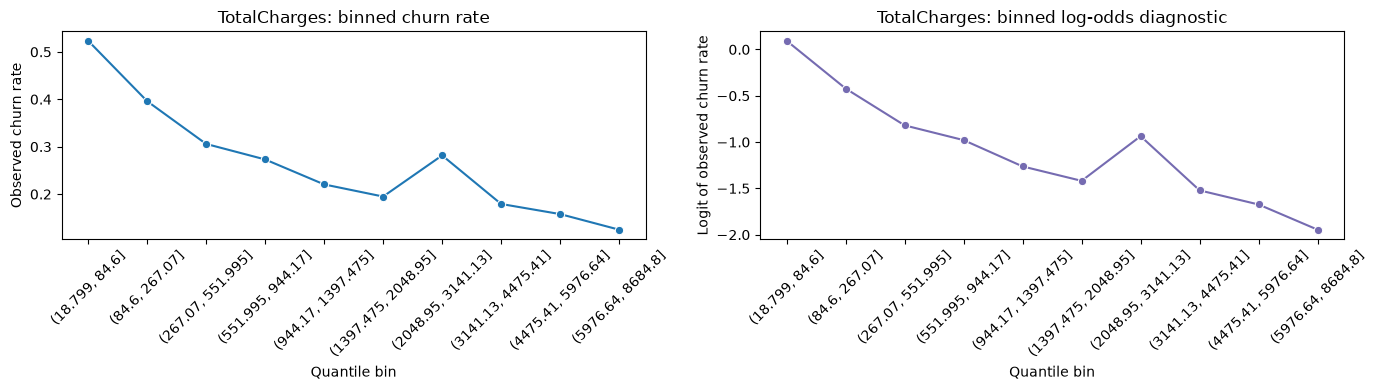

In [2]:
# Quantile-bin diagnostics: churn rates reveal monotonicity, thresholds, saturation, and non-monotonic patterns.
binned_tables = {}
for feature in continuous_features:
    rates = binned_churn_rates(data, feature, target="Churn", bins=10).copy()
    clipped_rate = rates["churn_rate"].clip(0.001, 0.999)
    rates["logit_churn_rate"] = np.log(clipped_rate / (1 - clipped_rate))
    rates["bin_label"] = rates["bin"].astype(str)
    binned_tables[feature] = rates
    print(f"{feature}: {diagnose_relationship(rates)}")
    display(rates)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.lineplot(data=rates, x="bin_label", y="churn_rate", marker="o", ax=axes[0])
    axes[0].set_title(f"{feature}: binned churn rate")
    axes[0].set_xlabel("Quantile bin")
    axes[0].set_ylabel("Observed churn rate")
    axes[0].tick_params(axis="x", rotation=45)
    sns.lineplot(data=rates, x="bin_label", y="logit_churn_rate", marker="o", color="#756bb1", ax=axes[1])
    axes[1].set_title(f"{feature}: binned log-odds diagnostic")
    axes[1].set_xlabel("Quantile bin")
    axes[1].set_ylabel("Logit of observed churn rate")
    axes[1].tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

In [3]:
# Transformation diagnostics are descriptive only. Tree models do not require these transformations automatically.
def safe_transform(values, name):
    positive_values = values.clip(lower=0)
    if name == "identity":
        return values
    if name == "log1p":
        return np.log1p(positive_values)
    if name == "sqrt":
        return np.sqrt(positive_values)
    if name == "square":
        return values ** 2
    if name == "cube":
        return values ** 3
    raise ValueError(f"Unknown transformation: {name}")

transformations = ["identity", "log1p", "sqrt", "square", "cube"]
transformation_rows = []
for feature in continuous_features:
    values = data[[feature, "Churn"]].dropna()
    for transformation in transformations:
        transformed = safe_transform(values[feature], transformation)
        spearman_result = stats.spearmanr(transformed, values["Churn"] )
        pearson_result = stats.pearsonr(transformed, values["Churn"] )
        transformation_rows.append({"feature": feature, "transformation": transformation, "pearson_r": float(pearson_result[0]), "pearson_p": float(pearson_result[1]), "spearman_r": float(spearman_result[0]), "spearman_p": float(spearman_result[1])})
transformation_table = pd.DataFrame(transformation_rows)
transformation_table["absolute_spearman"] = transformation_table["spearman_r"].abs()
transformation_table.sort_values(["feature", "absolute_spearman"], ascending=[True, False])

,feature,transformation,pearson_r,pearson_p,spearman_r,spearman_p,absolute_spearman
5,MonthlyCharges,identity,0.193356,2.706646e-60,0.184743,4.132386e-55,0.184743
6,MonthlyCharges,log1p,0.210109,4.198457e-71,0.184743,4.132386e-55,0.184743
7,MonthlyCharges,sqrt,0.203373,1.219118e-66,0.184743,4.132386e-55,0.184743
8,MonthlyCharges,square,0.167271,2.311376e-45,0.184743,4.132386e-55,0.184743
9,MonthlyCharges,cube,0.139097,9.118457e-32,0.184743,4.132386e-55,0.184743
10,TotalCharges,identity,-0.199484,4.876866e-64,-0.232190,1.023989e-86,0.232190
11,TotalCharges,log1p,-0.241908,3.475067e-94,-0.232190,1.023989e-86,0.232190
12,TotalCharges,sqrt,-0.225189,1.519466e-81,-0.232190,1.023989e-86,0.232190
13,TotalCharges,square,-0.166620,5.952987e-45,-0.232190,1.023989e-86,0.232190
14,TotalCharges,cube,-0.147401,1.880776e-35,-0.232190,1.023989e-86,0.232190


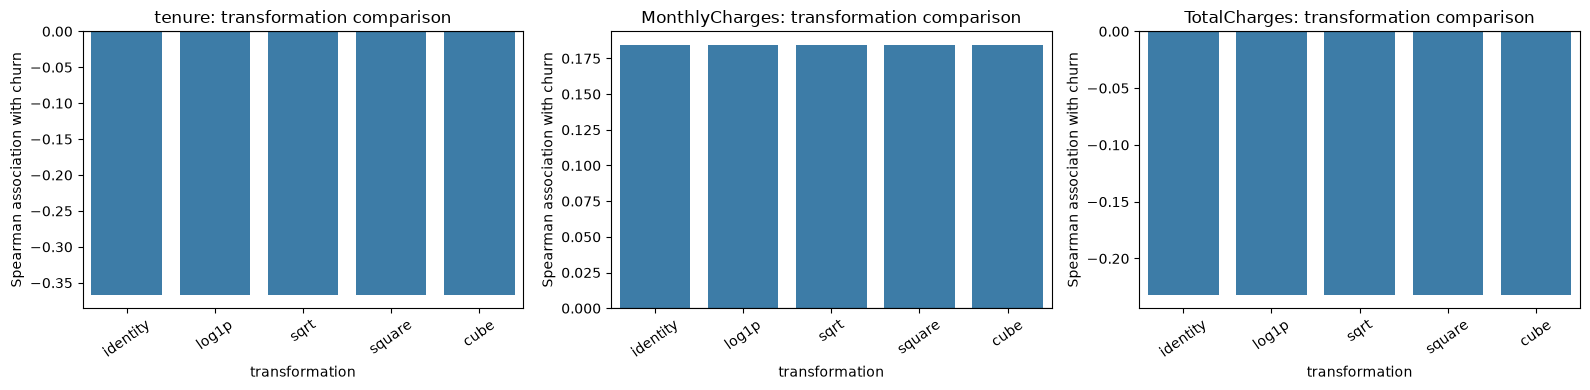

In [4]:
# Compare transformation association strength without treating correlation as proof of linearity.
fig, axes = plt.subplots(1, len(continuous_features), figsize=(16, 4))
for axis, feature in zip(axes, continuous_features):
    current = transformation_table[transformation_table["feature"] == feature].copy()
    sns.barplot(data=current, x="transformation", y="spearman_r", color="#2c7fb8", ax=axis)
    axis.axhline(0, color="black", linewidth=0.8)
    axis.set_title(f"{feature}: transformation comparison")
    axis.set_ylabel("Spearman association with churn")
    axis.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

,feature,mutual_information
0,tenure,0.067288
2,TotalCharges,0.044694
1,MonthlyCharges,0.039818


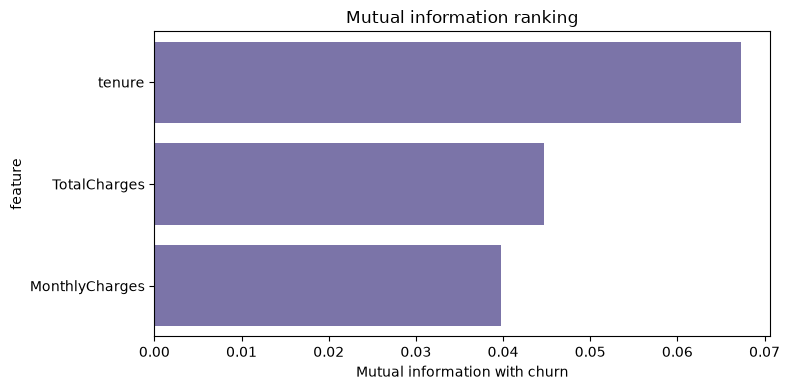

In [5]:
# Mutual information captures dependency beyond a single linear correlation.
# It is comparative evidence of dependence, not evidence of causality.
mi_input = data[continuous_features].copy()
mi_input = mi_input.fillna(mi_input.median())
mi_scores = mutual_info_classif(mi_input, data["Churn"], random_state=42)
mutual_information_table = pd.DataFrame({"feature": continuous_features, "mutual_information": mi_scores}).sort_values("mutual_information", ascending=False)
display(mutual_information_table)
plt.figure(figsize=(8, 4))
sns.barplot(data=mutual_information_table, x="mutual_information", y="feature", color="#756bb1")
plt.title("Mutual information ranking")
plt.xlabel("Mutual information with churn")
plt.tight_layout()
plt.show()

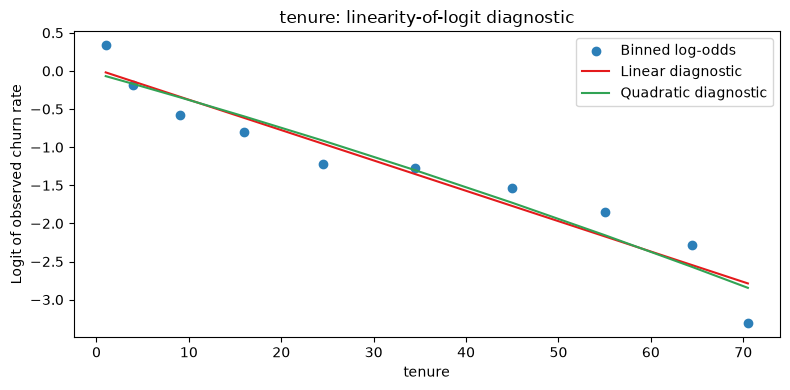

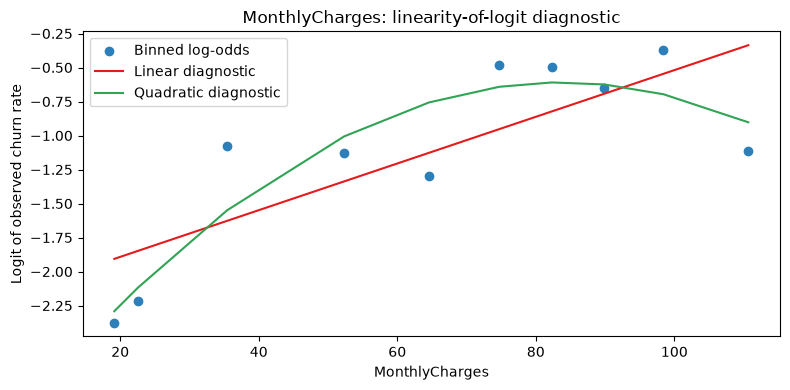

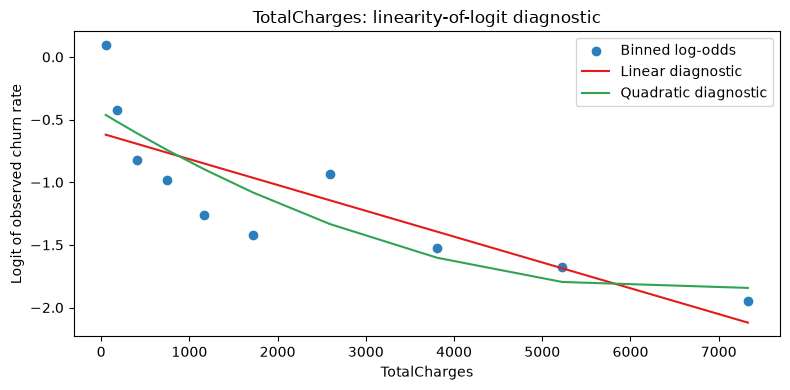

,feature,linear_r2,quadratic_r2,quadratic_gain
0,tenure,0.920785,0.922203,0.001418
1,MonthlyCharges,0.613047,0.832375,0.219328
2,TotalCharges,0.675720,0.745309,0.069589


In [6]:
# Log-odds diagnostics compare a straight-line fit with a quadratic descriptive fit.
# This is a statistical shape diagnostic, not a final predictive model.
logit_diagnostic_rows = []
for feature, rates in binned_tables.items():
    valid = rates.dropna(subset=[feature, "logit_churn_rate"]).copy() if feature in rates.columns else rates.dropna(subset=["logit_churn_rate"]).copy()
    if "bin_midpoint" not in valid.columns:
        intervals = valid["bin"].apply(lambda value: value.mid)
        valid["bin_midpoint"] = intervals.astype(float)
    x = valid["bin_midpoint"].to_numpy()
    y = valid["logit_churn_rate"].to_numpy()
    linear_coefficients = np.polyfit(x, y, 1)
    quadratic_coefficients = np.polyfit(x, y, 2)
    linear_predicted = np.polyval(linear_coefficients, x)
    quadratic_predicted = np.polyval(quadratic_coefficients, x)
    total_variation = np.sum((y - y.mean()) ** 2)
    linear_r2 = 1 - np.sum((y - linear_predicted) ** 2) / total_variation if total_variation else np.nan
    quadratic_r2 = 1 - np.sum((y - quadratic_predicted) ** 2) / total_variation if total_variation else np.nan
    logit_diagnostic_rows.append({"feature": feature, "linear_r2": linear_r2, "quadratic_r2": quadratic_r2, "quadratic_gain": quadratic_r2 - linear_r2})
    plt.figure(figsize=(8, 4))
    plt.scatter(x, y, color="#2c7fb8", label="Binned log-odds")
    order = np.argsort(x)
    plt.plot(x[order], linear_predicted[order], color="#e41a1c", label="Linear diagnostic")
    plt.plot(x[order], quadratic_predicted[order], color="#31a354", label="Quadratic diagnostic")
    plt.title(f"{feature}: linearity-of-logit diagnostic")
    plt.xlabel(feature)
    plt.ylabel("Logit of observed churn rate")
    plt.legend()
    plt.tight_layout()
    plt.show()
logit_diagnostic_table = pd.DataFrame(logit_diagnostic_rows)
logit_diagnostic_table

In [7]:
# Interaction diagnostics use observed grouped churn rates, not a separate predictive model.
interaction_definitions = {
    "Contract x tenure": ["Contract", "tenure"],
    "Contract x MonthlyCharges": ["Contract", "MonthlyCharges"],
    "InternetService x TechSupport": ["InternetService", "TechSupport"],
    "InternetService x OnlineSecurity": ["InternetService", "OnlineSecurity"],
    "SeniorCitizen x Contract": ["SeniorCitizen", "Contract"],
    "PaymentMethod x Contract": ["PaymentMethod", "Contract"],
}
interaction_tables = {}
for name, columns in interaction_definitions.items():
    if columns[1] in continuous_features:
        working = data[[columns[0], columns[1], "Churn"]].dropna().copy()
        working["value_bin"] = pd.qcut(working[columns[1]], q=5, duplicates="drop")
        grouped = working.groupby([columns[0], "value_bin"], observed=True)["Churn"].agg(customer_count="size", churn_rate="mean").reset_index()
    else:
        grouped = data.groupby(columns, dropna=False)["Churn"].agg(customer_count="size", churn_rate="mean").reset_index()
    grouped["churn_rate_pct"] = grouped["churn_rate"] * 100
    interaction_tables[name] = grouped
    print(f"\n{name}")
    display(grouped.sort_values("churn_rate", ascending=False).head(15))


Contract x tenure


,Contract,value_bin,customer_count,churn_rate,churn_rate_pct
0,Month-to-month,"(-0.001, 6.0]",1413,0.552017,55.201699
1,Month-to-month,"(6.0, 20.0]",1105,0.406335,40.633484
2,Month-to-month,"(20.0, 40.0]",816,0.335784,33.578431
3,Month-to-month,"(40.0, 60.0]",433,0.295612,29.561201
4,Month-to-month,"(60.0, 72.0]",108,0.222222,22.222222
8,One year,"(40.0, 60.0]",506,0.134387,13.438735
9,One year,"(60.0, 72.0]",313,0.121406,12.140575
5,One year,"(-0.001, 6.0]",39,0.102564,10.256410
7,One year,"(20.0, 40.0]",414,0.091787,9.178744
6,One year,"(6.0, 20.0]",201,0.089552,8.955224



Contract x MonthlyCharges


,Contract,value_bin,customer_count,churn_rate,churn_rate_pct
4,Month-to-month,"(94.25, 118.75]",648,0.537037,53.703704
3,Month-to-month,"(79.1, 94.25]",913,0.521358,52.135816
2,Month-to-month,"(58.83, 79.1]",866,0.448037,44.803695
1,Month-to-month,"(25.05, 58.83]",902,0.361419,36.141907
9,One year,"(94.25, 118.75]",386,0.225389,22.538860
0,Month-to-month,"(18.249, 25.05]",546,0.214286,21.428571
8,One year,"(79.1, 94.25]",202,0.118812,11.881188
7,One year,"(58.83, 79.1]",288,0.100694,10.069444
14,Two year,"(94.25, 118.75]",374,0.072193,7.219251
6,One year,"(25.05, 58.83]",250,0.068000,6.800000



InternetService x TechSupport


...

,InternetService,OnlineSecurity,customer_count,churn_rate,churn_rate_pct
2,Fiber optic,No,2257,0.493576,49.357554
0,DSL,No,1241,0.279613,27.961322
3,Fiber optic,Yes,839,0.218117,21.811681
1,DSL,Yes,1180,0.094915,9.491525
4,No,No internet service,1526,0.074050,7.404980



SeniorCitizen x Contract


,SeniorCitizen,Contract,customer_count,churn_rate,churn_rate_pct
3,1,Month-to-month,807,0.546468,54.646840
0,0,Month-to-month,3068,0.395698,39.569752
4,1,One year,190,0.152632,15.263158
1,0,One year,1283,0.106781,10.678098
5,1,Two year,145,0.041379,4.137931
2,0,Two year,1550,0.027097,2.709677



PaymentMethod x Contract


,PaymentMethod,Contract,customer_count,churn_rate,churn_rate_pct
6,Electronic check,Month-to-month,1850,0.537297,53.729730
0,Bank transfer (automatic),Month-to-month,589,0.341256,34.125637
3,Credit card (automatic),Month-to-month,543,0.327808,32.780847
9,Mailed check,Month-to-month,893,0.315789,31.578947
7,Electronic check,One year,347,0.184438,18.443804
4,Credit card (automatic),One year,398,0.103015,10.301508
1,Bank transfer (automatic),One year,391,0.097187,9.718670
8,Electronic check,Two year,168,0.077381,7.738095
10,Mailed check,One year,337,0.068249,6.824926
2,Bank transfer (automatic),Two year,564,0.033688,3.368794


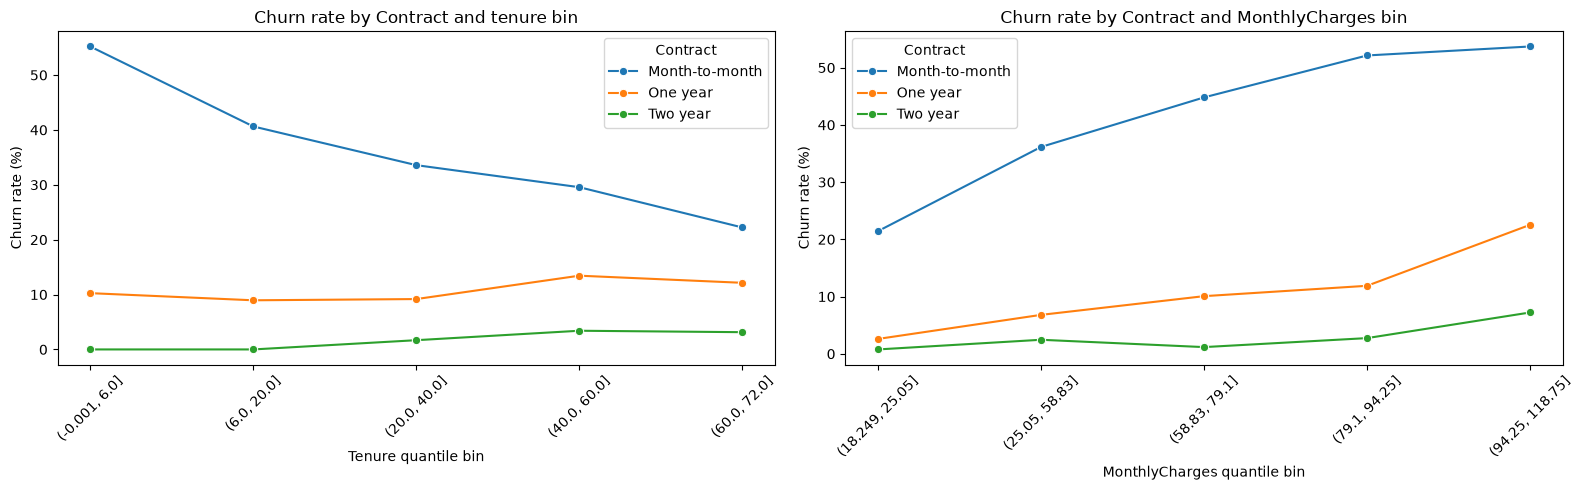

In [8]:
# Visualize two interaction examples and keep count separate from churn rate.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
contract_tenure = interaction_tables["Contract x tenure"].copy()
contract_tenure["value_bin_label"] = contract_tenure["value_bin"].astype(str)
sns.lineplot(data=contract_tenure, x="value_bin_label", y="churn_rate_pct", hue="Contract", marker="o", ax=axes[0])
axes[0].set_title("Churn rate by Contract and tenure bin")
axes[0].set_xlabel("Tenure quantile bin")
axes[0].set_ylabel("Churn rate (%)")
axes[0].tick_params(axis="x", rotation=45)
contract_monthly = interaction_tables["Contract x MonthlyCharges"].copy()
contract_monthly["value_bin_label"] = contract_monthly["value_bin"].astype(str)
sns.lineplot(data=contract_monthly, x="value_bin_label", y="churn_rate_pct", hue="Contract", marker="o", ax=axes[1])
axes[1].set_title("Churn rate by Contract and MonthlyCharges bin")
axes[1].set_xlabel("MonthlyCharges quantile bin")
axes[1].set_ylabel("Churn rate (%)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## Interpretation rules
- Normality tests describe distributional assumptions; they do not determine whether a feature-to-churn relationship is linear.
- Binned churn rates reveal monotonicity, thresholds, saturation, U-shapes, and interaction-dependent patterns.
- Log-odds diagnostics assess whether a straight-line description is adequate; a higher quadratic fit is evidence of curvature, not proof of causality.
- Transformations are compared descriptively and are not automatically added to tree-based models.
- Mutual information detects comparative dependency beyond a single correlation coefficient, but it does not establish causality.
- Interaction tables use observed churn rates and customer counts. They are descriptive evidence and must not be interpreted as causal effects.

## Outcome and usefulness

### Outcome
- Quantile-binned churn rates show that `tenure` has a strong monotonic pattern: churn is highest among the shortest-tenure customers and declines as tenure increases.
- `MonthlyCharges` is threshold-driven and non-monotonic across bins. Its binned log-odds are described better by a quadratic diagnostic than by a straight-line diagnostic, which is evidence of curvature rather than proof of causality.
- `TotalCharges` generally declines in churn rate as accumulated charges increase, but the pattern is not perfectly monotonic because total charges also encode tenure and billing history.
- Transformation diagnostics compare identity, `log1p`, square root, square, and cube forms. These comparisons are descriptive evidence; transformations are not automatically added to XGBoost or CatBoost.
- Mutual information ranks `tenure` highest among the continuous features, followed by `TotalCharges` and `MonthlyCharges` in the observed run.
- Interaction tables show that contract type changes the relationship between tenure and monthly charges and churn. Additional grouped diagnostics cover internet service with support/security, senior-citizen status with contract, and payment method with contract.
- The notebook explicitly separates normality from linearity, correlation from causation, and descriptive interaction evidence from predictive modeling.

### Why this is useful
- It prevents the incorrect conclusion that a nonlinear model alone proves that the data is nonlinear.
- It shows where a simple linear or monotonic description may be inadequate, guiding feature representation and interpretation.
- It identifies threshold and interaction patterns that tree models can capture naturally.
- It helps explain model behavior to stakeholders using observed churn-rate curves and segments rather than opaque importance scores alone.
- It provides diagnostic evidence for deciding whether transformations, bins, interactions, or native categorical handling are worth testing.
- It protects the project from causal overstatement: these are observed associations and model diagnostics, not intervention effects.

### Modeling hand-off
Retain the raw continuous variables as the primary candidates, test engineered or transformed variants only through development validation, and allow XGBoost/CatBoost to model interactions. Do not use these diagnostics as a substitute for cross-validation or final test evaluation.